In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "raw_data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.drop("customerID",axis=1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.drop('customerID',axis=1,inplace=True)

In [8]:
def discovering_data(data):
    print("number of rows and columns:", data.shape)
    print("data types of the columns:", data.dtypes)
    # print("checking for nulls :",data.isnull().sum())
    print("numeric columns :",df.select_dtypes(include="int").columns.to_list())
    print("categorical columns :",df.select_dtypes(include="object").columns.to_list())
discovering_data(df) 


number of rows and columns: (7043, 20)
data types of the columns: gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
numeric columns : ['SeniorCitizen', 'tenure']
categorical columns : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [9]:
def checking_nulls_duplicates(data):
    print(f"checking nulls of the colums{df.isnull().sum()}")
    print(f"checking duplicates:{data.duplicated().sum()}")
checking_nulls_duplicates(df)

checking nulls of the columsgender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
checking duplicates:22


In [10]:
categorical_data=df.select_dtypes(include="object").columns.tolist()
for cols in categorical_data:
    print(f"n. of unique values {cols}: {df[cols].nunique()}")



n. of unique values gender: 2
n. of unique values Partner: 2
n. of unique values Dependents: 2
n. of unique values PhoneService: 2
n. of unique values MultipleLines: 3
n. of unique values InternetService: 3
n. of unique values OnlineSecurity: 3
n. of unique values OnlineBackup: 3
n. of unique values DeviceProtection: 3
n. of unique values TechSupport: 3
n. of unique values StreamingTV: 3
n. of unique values StreamingMovies: 3
n. of unique values Contract: 3
n. of unique values PaperlessBilling: 2
n. of unique values PaymentMethod: 4
n. of unique values TotalCharges: 6531
n. of unique values Churn: 2


In [11]:
df["MonthlyCharges"].apply(lambda x: isinstance(x, str)).sum()
#method for detecting if the column has any strings in a numeric column

np.int64(0)

In [12]:
SchemeColumn={
    'gender':str,
    'SeniorCitizen':int,
    'Partner':str,
    'Dependents':str,
    'tenure':int,
    'PhoneService':str,
    'MultipleLines':str,
    'InternetService':str,
    'OnlineSecurity':str,
     'OnlineBackup':str,
     'DeviceProtection':str,
     'TechSupport':str,
     'StreamingTV':str,
     'StreamingMovies':str,
     'Contract':str,
     'PaperlessBilling':str,
     'PaymentMethod':str,
     'MonthlyCharges':float,
     'TotalCharges':float,
     'Churn':str
}

for column, expected_dtype in SchemeColumn.items():
    if df[column].dtype != expected_dtype:
        print(f"{column}: expected {expected_dtype}, got {df[column].dtype}")

gender: expected <class 'str'>, got object
Partner: expected <class 'str'>, got object
Dependents: expected <class 'str'>, got object
PhoneService: expected <class 'str'>, got object
MultipleLines: expected <class 'str'>, got object
InternetService: expected <class 'str'>, got object
OnlineSecurity: expected <class 'str'>, got object
OnlineBackup: expected <class 'str'>, got object
DeviceProtection: expected <class 'str'>, got object
TechSupport: expected <class 'str'>, got object
StreamingTV: expected <class 'str'>, got object
StreamingMovies: expected <class 'str'>, got object
Contract: expected <class 'str'>, got object
PaperlessBilling: expected <class 'str'>, got object
PaymentMethod: expected <class 'str'>, got object
TotalCharges: expected <class 'float'>, got object
Churn: expected <class 'str'>, got object


In [13]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"], errors="coerce")

In [14]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [15]:
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Distribution of MonthlyCharges: mean=64.76169246059918, median=70.35, std=30.090047097678493


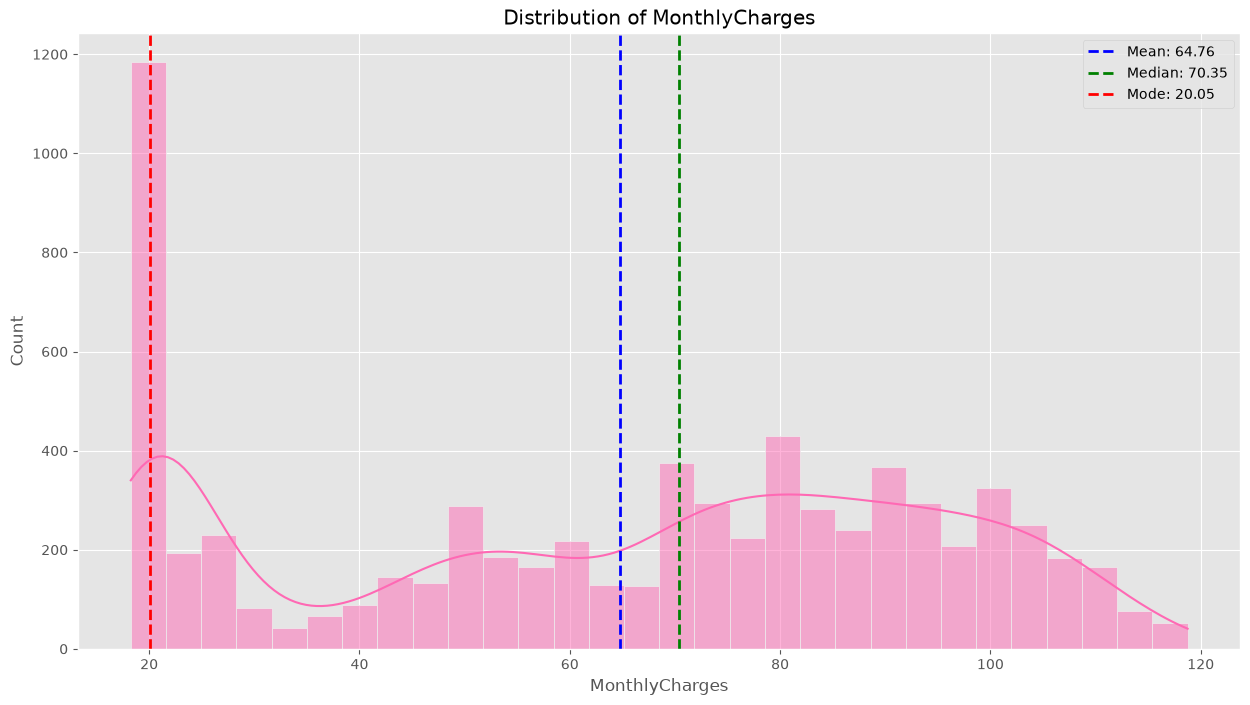

Distribution of TotalCharges: mean=2283.3004408418656, median=1397.475, std=2266.771361883145


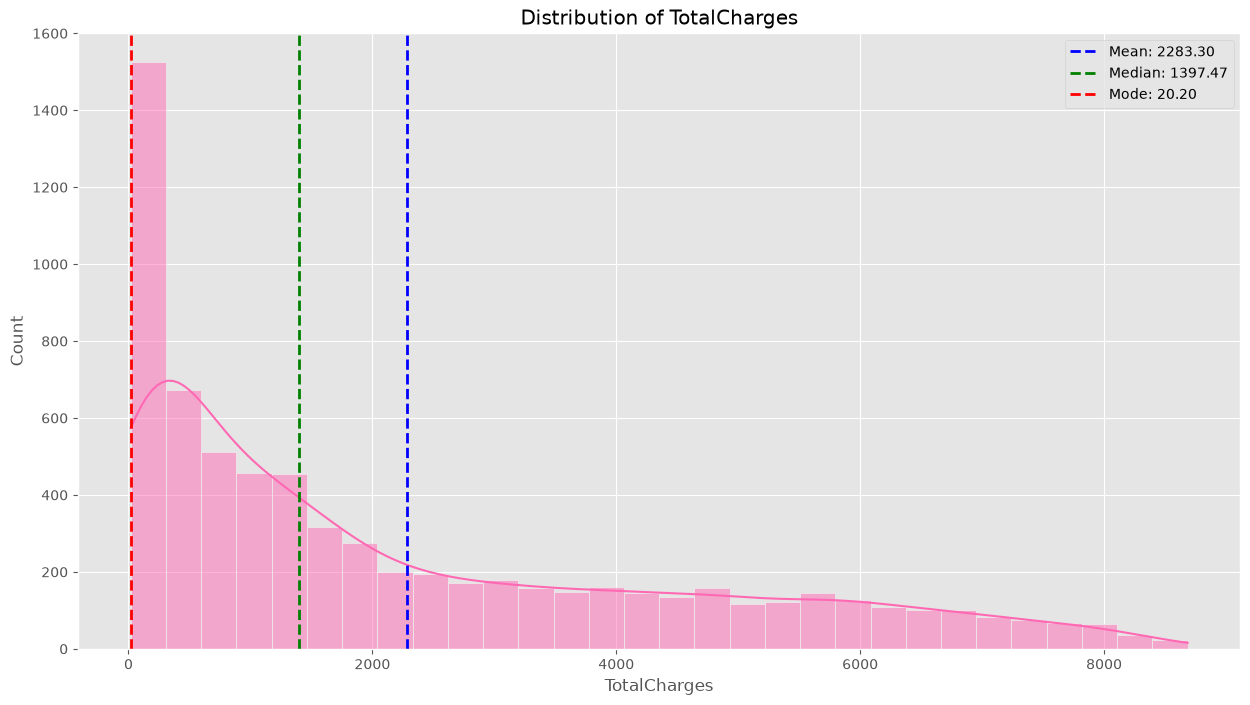

In [16]:
# checking the distribution of the data 
plt.style.use("ggplot")
def distribution(data,col):
    mean=data[col].mean()
    median=data[col].median()
    std=data[col].std()
    mode=data[col].mode()[0]
    print(f"Distribution of {col}: mean={mean}, median={median}, std={std}")
    plt.figure(figsize=(15,8))
    sns.histplot(data[col], kde=True, bins=30,color="hotpink")
    plt.title(f"Distribution of {col}")
    plt.axvline(mean, color='blue', linestyle='dashed', linewidth=2, label=f'Mean: {mean:.2f}')
    plt.axvline(median, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median:.2f}')
    plt.axvline(mode, color='red', linestyle='dashed', linewidth=2, label=f'Mode: {mode:.2f}')
    plt.xlabel(col)
    plt.legend()
    plt.show()
   
for col in df.select_dtypes(include="float").columns:
    distribution(df,col)

In [17]:
median_tot_ch=df["TotalCharges"].median()
df["TotalCharges"]=df["TotalCharges"].fillna(median_tot_ch)

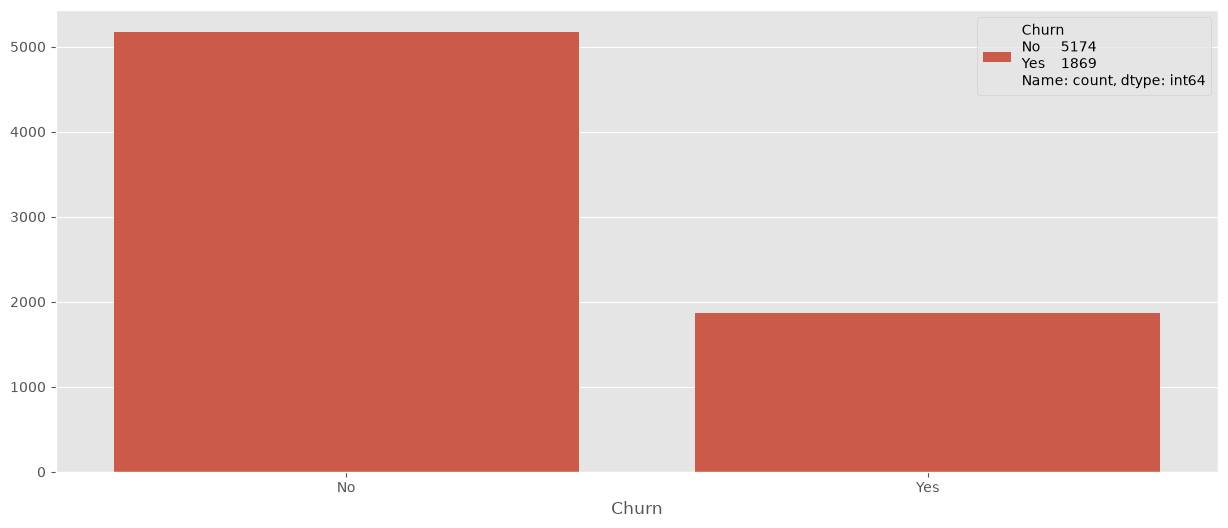

In [18]:
# data balance
categories=df["Churn"].value_counts()
plt.figure(figsize=(15,6))
sns.barplot(x=categories.index,y=categories.values,label=f"{categories}")
plt.legend()
plt.show()

In [19]:
df.select_dtypes(include="float").describe()

,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000
mean,64.761692,2281.916928
std,30.090047,2265.270398
min,18.250000,18.800000
25%,35.500000,402.225000
50%,70.350000,1397.475000
75%,89.850000,3786.600000
max,118.750000,8684.800000



Column: MonthlyCharges
Skewness: -0.22
Excess kurtosis: -1.26
Shapiro statistic: 0.9209
P-value: 2.23e-51
Shapiro-Wilk test
Evidence against normality (reject H0)


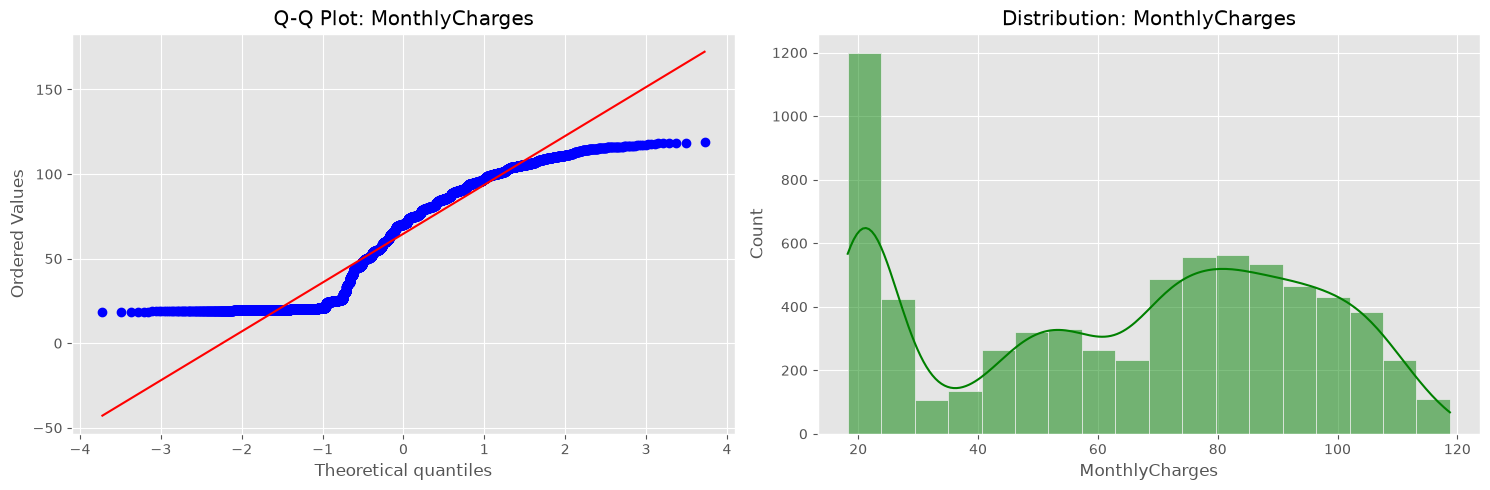


Column: TotalCharges
Skewness: 0.96
Excess kurtosis: -0.23
Shapiro statistic: 0.8603
P-value: 9.498e-62
Shapiro-Wilk test
Evidence against normality (reject H0)


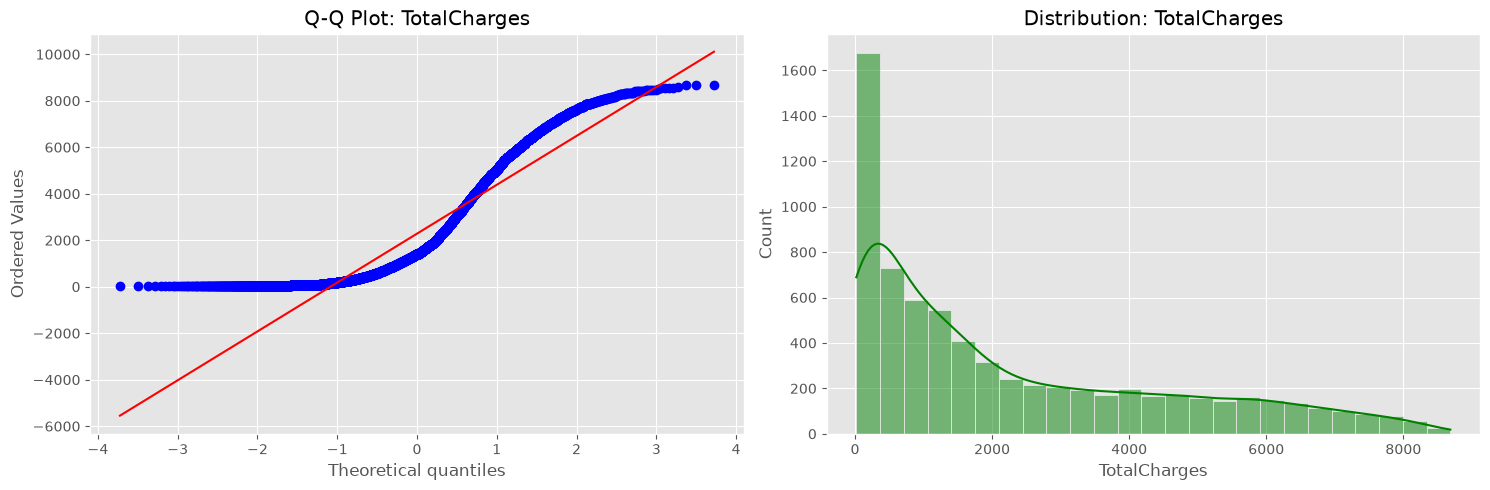

In [20]:

from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.select_dtypes(include=["float"]).columns:
    values = df[col].dropna()
    skewness = values.skew()
    kurtosis = values.kurt()
    stat, p_value = stats.shapiro(values)
    print(f"\nColumn: {col}")
    print(f"Skewness: {skewness:.2f}")
    print(f"Excess kurtosis: {kurtosis:.2f}")
    print(f"Shapiro statistic: {stat:.4f}")
    print(f"P-value: {p_value:.4g}")
    print("Shapiro-Wilk test")
    if p_value < 0.05:
        print("Evidence against normality (reject H0)")
    else:
        print("Insufficient evidence to reject normality")
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    stats.probplot(values, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot: {col}")
    plt.subplot(1, 2, 2)
    sns.histplot(values, color="green", kde=True)
    plt.title(f"Distribution: {col}")
    plt.tight_layout()
    plt.show()


In [21]:
# handling nulls by median as the distribution of the monthly charge is skewed 
median=df["MonthlyCharges"].median()
df["MonthlyCharges"]=df["MonthlyCharges"].fillna(median)

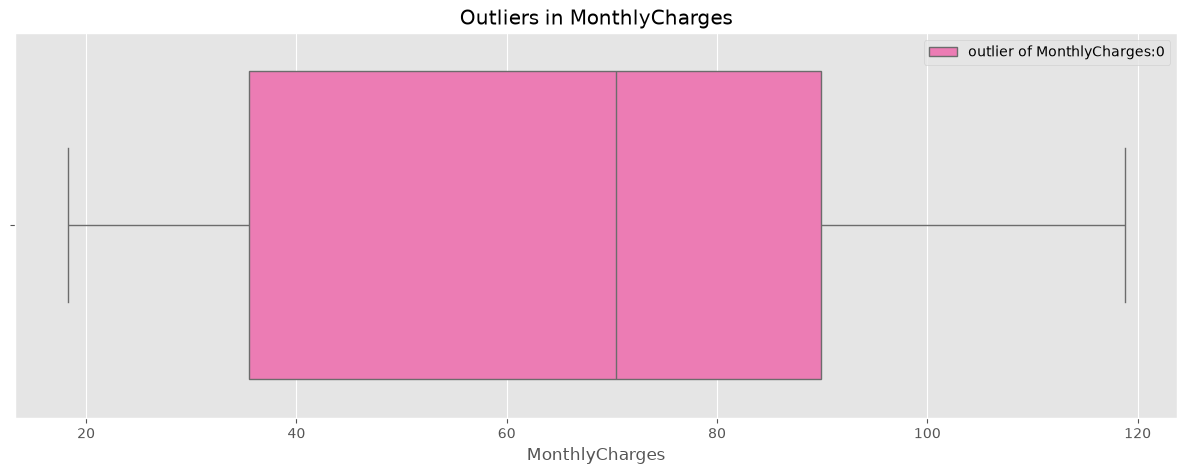

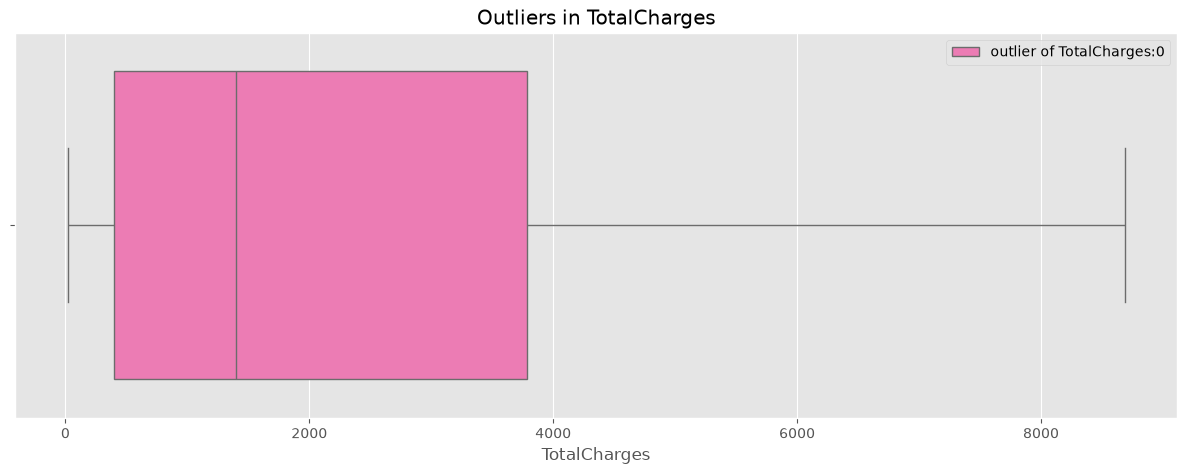

In [22]:
def checking_outliers(data,col):
        Q1=data[col].quantile(0.25)
        Q3=data[col].quantile(0.75)
        IQR=Q3-Q1
        upper_limit=Q3+1.5*IQR
        lower_limit=Q1-1.5*IQR
        outlier_mask=(data[col]<lower_limit)|(data[col]>upper_limit)
        plt.figure(figsize=(15,5))
        sns.boxplot(x=data[col],color="hotpink",label=f"outlier of {col}:{outlier_mask.sum()}")
        plt.legend()
        plt.title(f"Outliers in {col}")
        plt.show()

for col in ["MonthlyCharges","TotalCharges"]:
        checking_outliers(df,col)

In [23]:

from scipy.stats import chi2_contingency
def calc_corr_of_categorical(data,col,target="Churn"):
    table = pd.crosstab(data[col], data[target])
    chi2_stat, p_value, dof, _ = chi2_contingency(table)

    n = table.values.sum()
    r = table.shape[0]
    c = table.shape[1]

    cramers_v = np.sqrt(chi2_stat / (n * min(r-1, c-1)))

    return {
        "Feature": col,
        "Chi-square": chi2_stat,
        "P-value": p_value,
        "Degrees of Freedom": dof,
        "Cramer's V": cramers_v,
        "Association": "Significant" if p_value < 0.05 else "Not Significant"
    }
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.drop("Churn", errors="ignore")
results1 = pd.DataFrame(
    [calc_corr_of_categorical(df, col) for col in categorical_cols]
).sort_values(by="Cramer's V",ascending=False)
results1

,Feature,Chi-square,P-value,Degrees of Freedom,Cramer's V,Association
12,Contract,1184.596572,5.863038e-258,2,0.410116,Significant
6,OnlineSecurity,849.998968,2.661150e-185,2,0.347400,Significant
9,TechSupport,828.197068,1.443084e-180,2,0.342916,Significant
5,InternetService,732.309590,9.571788e-160,2,0.322455,Significant
14,PaymentMethod,648.142327,3.682355e-140,3,0.303359,Significant
7,OnlineBackup,601.812790,2.079759e-131,2,0.292316,Significant
8,DeviceProtection,558.419369,5.505219e-122,2,0.281580,Significant
11,StreamingMovies,375.661479,2.667757e-82,2,0.230951,Significant
10,StreamingTV,374.203943,5.528994e-82,2,0.230502,Significant
13,PaperlessBilling,258.277649,4.073355e-58,1,0.191498,Significant


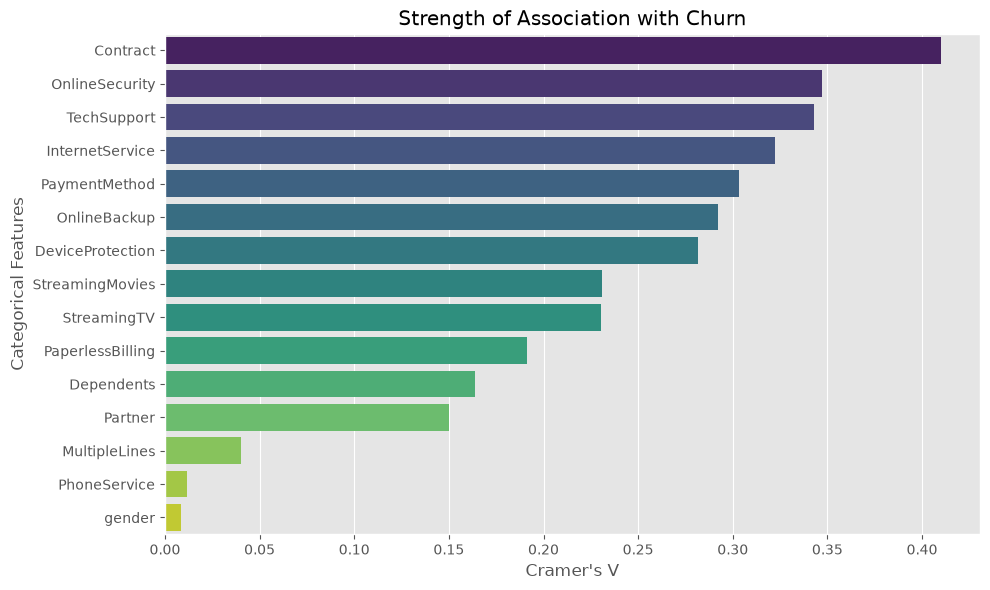

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x=results1["Cramer\'s V"],
    y=results1["Feature"],
    palette="viridis",
    legend=False
)

plt.title("Strength of Association with Churn")
plt.xlabel("Cramer's V")
plt.ylabel("Categorical Features")
plt.tight_layout()
plt.show()

In [25]:
from scipy.stats import pointbiserialr
df["Churn_num"] = df["Churn"].map({"Yes": 1, "No": 0})
results = []

numerical_cols=df.select_dtypes(include=np.number)
for col in numerical_cols:
    corr, p_value = pointbiserialr(df[col], df["Churn_num"])

    results.append({
        "Feature": col,
        "Correlation": corr,
        "P-value": p_value
    })

results = pd.DataFrame(results)

results = results.sort_values(
    by="Correlation",
    ascending=False
)

results



,Feature,Correlation,P-value
4,Churn_num,1.000000,0.000000e+00
2,MonthlyCharges,0.193356,2.706646e-60
0,SeniorCitizen,0.150889,3.839860e-37
3,TotalCharges,-0.199037,7.508609e-64
1,tenure,-0.352229,7.999058e-205


Text(0.5, 1.0, 'Strength with Churn')

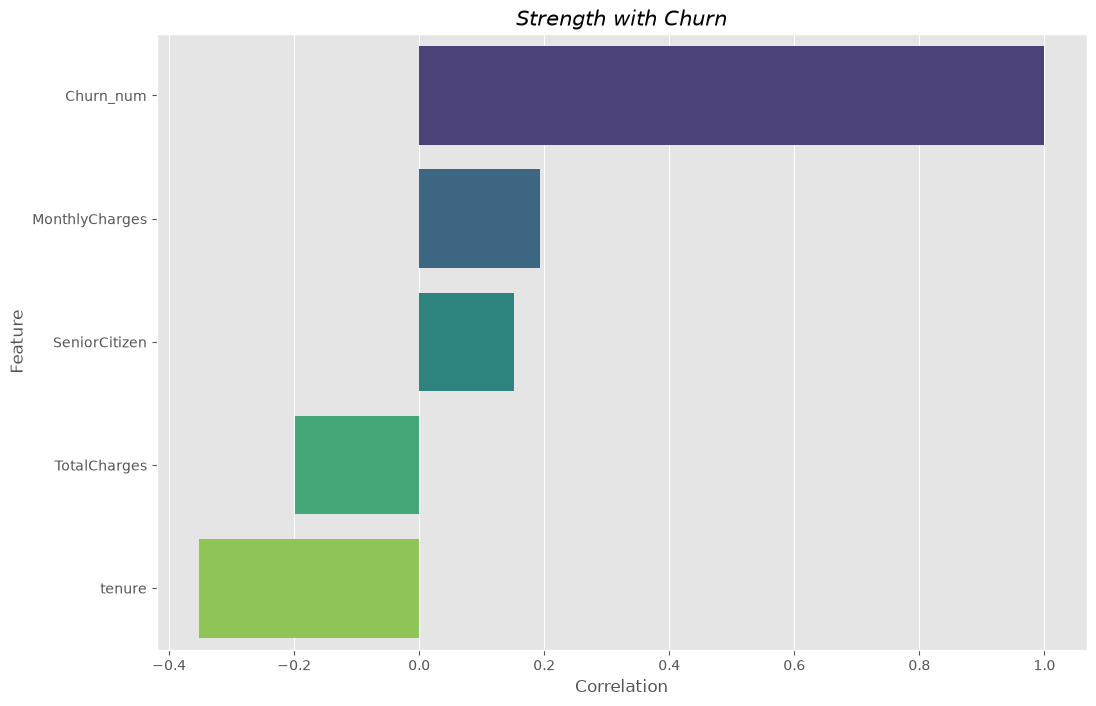

In [26]:
plt.figure(figsize=(12,8))
sns.barplot(data=df,x=results["Correlation"],y=results["Feature"],palette="viridis")
plt.title("Strength with Churn",fontsize=15,fontstyle="italic")


In [27]:
# some of EDA 
G1_churn=df[df["Churn"]=="Yes"]["MonthlyCharges"]
G2_churn=df[df["Churn"]=="No"]["MonthlyCharges"]

results2=pd.DataFrame({
    "Churned":{
        "Count":len(G1_churn),
        "Mean":G1_churn.mean(),
        "median":G1_churn.median(),
        "Std":G1_churn.std()

    },
    "Not Churned":{
            "Count":len(G2_churn),
            "Mean":G2_churn.mean(),
            "median":G2_churn.median(),
            "Std":G2_churn.std()
    
        }
})

results2.round(3)


,Churned,Not Churned
Count,1869.000,5174.000
Mean,74.441,61.265
median,79.650,64.425
Std,24.666,31.093


T-statistic: 18.408
Degrees of freedom: 4135.80
P-value: 0.00000
Critical t-value: ±1.961
There is a statistically significant difference in the two groups.


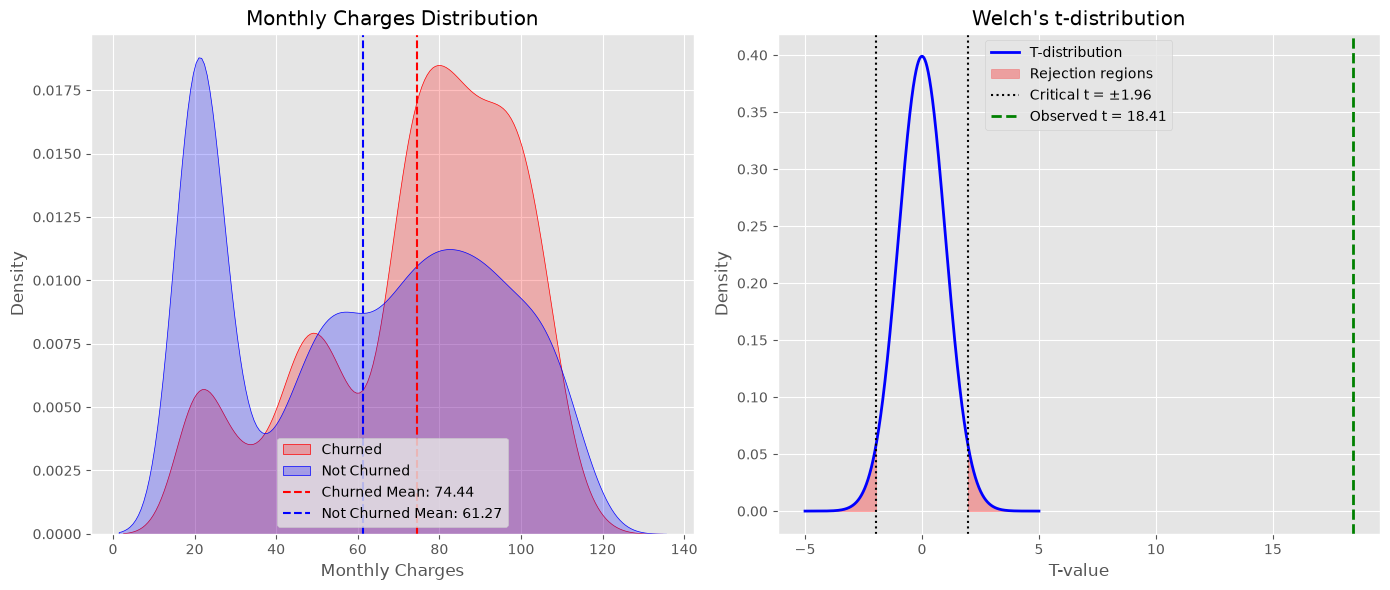

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, t

# 1. Welch's t-test
test_result = ttest_ind(
    G1_churn,
    G2_churn,
    equal_var=False
)

t_stat = test_result.statistic
p_value = test_result.pvalue
dof = test_result.df

alpha = 0.05

# 2. Calculate critical t-value
critical_t = t.ppf(1 - alpha/2, dof)

print(f"T-statistic: {t_stat:.3f}")
print(f"Degrees of freedom: {dof:.2f}")
print(f"P-value: {p_value:.5f}")
print(f"Critical t-value: ±{critical_t:.3f}")

if p_value < alpha:
    print("There is a statistically significant difference in the two groups.")
else:
    print("There is insufficient statistical evidence of a difference.")

# 3. Visualization
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# First plot: KDE distributions
sns.kdeplot(
    G1_churn,
    fill=True,
    color="red",
    label="Churned",
    ax=ax[0]
)

sns.kdeplot(
    G2_churn,
    fill=True,
    color="blue",
    label="Not Churned",
    ax=ax[0]
)

ax[0].axvline(
    G1_churn.mean(),
    color="red",
    linestyle="--",
    label=f"Churned Mean: {G1_churn.mean():.2f}"
)

ax[0].axvline(
    G2_churn.mean(),
    color="blue",
    linestyle="--",
    label=f"Not Churned Mean: {G2_churn.mean():.2f}"
)

ax[0].set_title("Monthly Charges Distribution")
ax[0].set_xlabel("Monthly Charges")
ax[0].legend()

# Second plot: Welch's theoretical t-distribution
x = np.linspace(-5, 5, 2000)
y = t.pdf(x, dof)

ax[1].plot(
    x, y,
    color="blue",
    linewidth=2,
    label="T-distribution"
)

# Shade rejection regions
ax[1].fill_between(
    x, y,
    where=(x <= -critical_t),
    color="red",
    alpha=0.3,
    label="Rejection regions"
)

ax[1].fill_between(
    x, y,
    where=(x >= critical_t),
    color="red",
    alpha=0.3
)

# Critical values
ax[1].axvline(
    critical_t,
    color="black",
    linestyle=":",
    label=f"Critical t = ±{critical_t:.2f}"
)

ax[1].axvline(
    -critical_t,
    color="black",
    linestyle=":"
)

# Observed t-statistic
ax[1].axvline(
    t_stat,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Observed t = {t_stat:.2f}"
)

ax[1].set_title("Welch's t-distribution")
ax[1].set_xlabel("T-value")
ax[1].set_ylabel("Density")
ax[1].legend()

plt.tight_layout()
plt.show()

ChargeGroup
Low          11.237230
Medium       24.575311
High         37.507114
Very High    32.878271
Name: Churn_num, dtype: float64


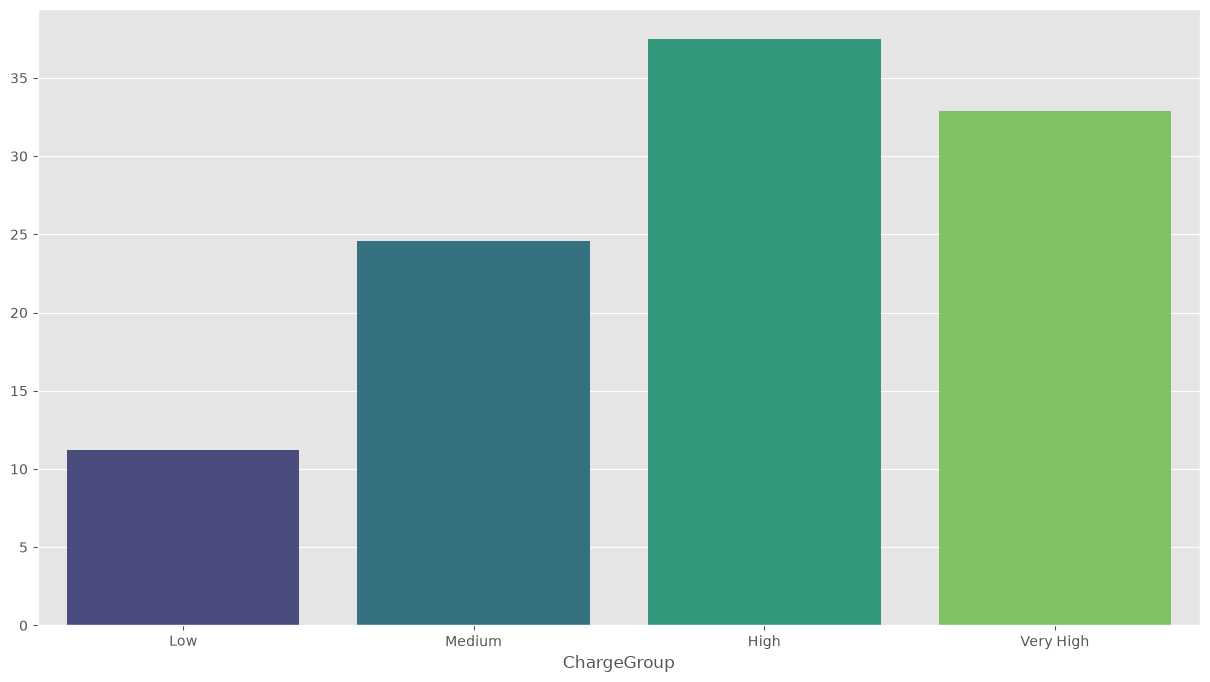

In [29]:
df["ChargeGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)
churn_rate = df.groupby(
    "ChargeGroup",
    observed=True
)["Churn_num"].mean() * 100

plt.figure(figsize=(15, 8))
sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values,
    palette="viridis"
)
print(churn_rate)
#that proof that people who has more rate of  monthly charges are most likely to churn from the company 

                mean  count
Contract                   
Month-to-month  43.0   3875
One year        11.0   1473
Two year         3.0   1695


Text(0.5, 1.0, 'Churning Rate Per Contract ')

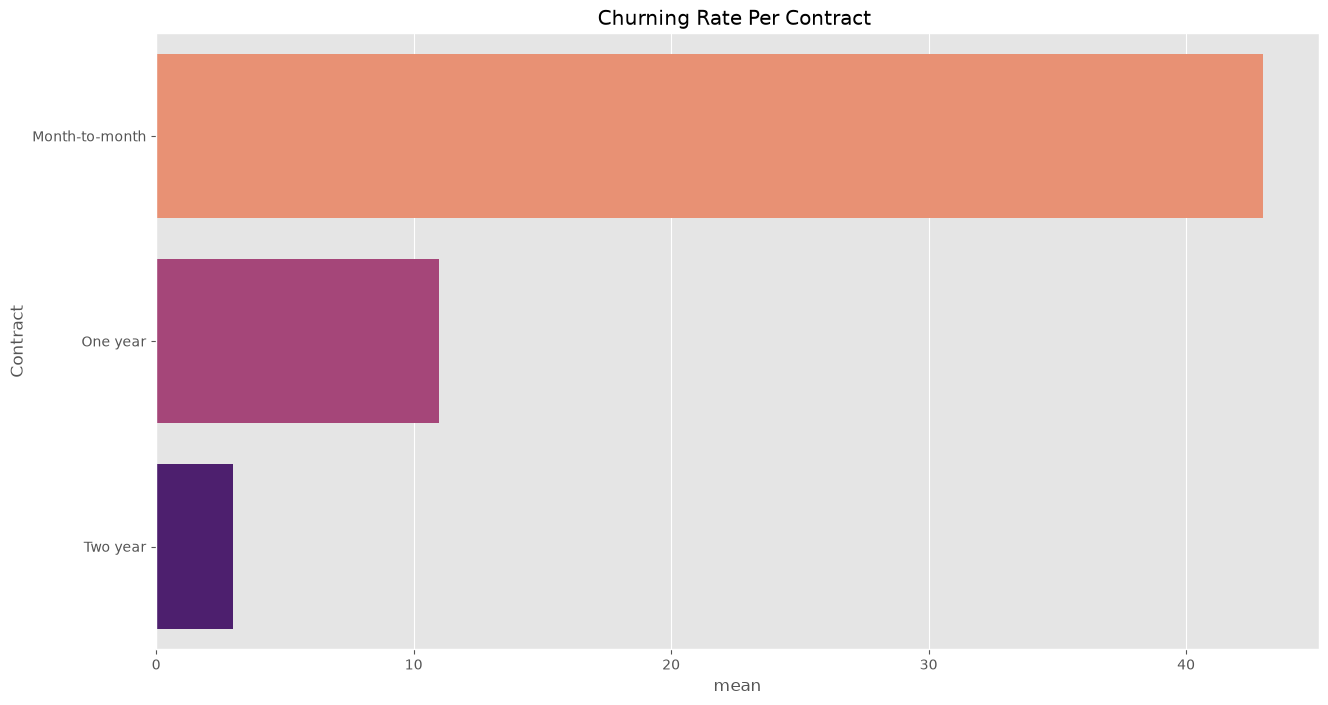

In [30]:
#churning per contract
contract_churn = (
    df.groupby("Contract")["Churn_num"]
      .agg(["mean", "count"]).round(2)
)
contract_churn["mean"] *= 100
print(contract_churn)
plt.figure(figsize=(15,8))
sns.barplot(x=contract_churn["mean"],y=contract_churn.index,palette="magma_r")
plt.title("Churning Rate Per Contract ")

# recommendations :
# Free premium service for the first three months.
#Priority technical support
#Offer a cheaper package with fewer services


In [31]:
my_list=[]
for col in df.columns:
    if df[col].nunique()==2:
        my_list.append(col)


print(my_list)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn', 'Churn_num']


In [32]:
for col in df[['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn', 'Churn_num']]:
    print(f"col is {col} and number of unique is :{df[col].unique()}")

col is gender and number of unique is :['Female' 'Male']
col is SeniorCitizen and number of unique is :[0 1]
col is Partner and number of unique is :['Yes' 'No']
col is Dependents and number of unique is :['No' 'Yes']
col is PhoneService and number of unique is :['No' 'Yes']
col is PaperlessBilling and number of unique is :['Yes' 'No']
col is Churn and number of unique is :['No' 'Yes']
col is Churn_num and number of unique is :[0 1]


In [33]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_num', 'ChargeGroup'],
      dtype='object')

In [34]:
df.drop("Churn",axis=1,inplace=True)

In [35]:
cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
df[cols] = df[cols].replace({"Yes": 1, "No": 0})

In [36]:
df["gender"]=df["gender"].replace({"Male":1,"Female":0})
df["gender"]

0       0
1       1
2       1
3       1
4       0
       ..
7038    1
7039    0
7040    0
7041    1
7042    1
Name: gender, Length: 7043, dtype: int64

In [37]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn_num,ChargeGroup
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0,Low
1,1,0,0,0,34,1,No,DSL,Yes,No,...,No,No,No,One year,0,Mailed check,56.95,1889.50,0,Medium
2,1,0,0,0,2,1,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1,Medium
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,...,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0,Medium
4,0,0,0,0,2,1,No,Fiber optic,No,No,...,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1,High


In [38]:
for col in df[["MultipleLines","InternetService","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract","PaymentMethod"]]:
    print(f"{col} and {df[col].unique()}")

MultipleLines and ['No phone service' 'No' 'Yes']
InternetService and ['DSL' 'Fiber optic' 'No']
OnlineSecurity and ['No' 'Yes' 'No internet service']
OnlineBackup and ['Yes' 'No' 'No internet service']
DeviceProtection and ['No' 'Yes' 'No internet service']
TechSupport and ['No' 'Yes' 'No internet service']
StreamingTV and ['No' 'Yes' 'No internet service']
StreamingMovies and ['No' 'Yes' 'No internet service']
Contract and ['Month-to-month' 'One year' 'Two year']
PaymentMethod and ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [39]:
from sklearn.model_selection import train_test_split
X=df.drop(columns=["Churn_num"])
y=df["Churn_num"]
x_train,x_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)
print(f"Training set size: {x_train.shape[0]}")
print(f"Test set size: {x_test.shape[0]}")


Training set size: 5634
Test set size: 1409


In [40]:
num_cols = [
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'PaperlessBilling',
 'MonthlyCharges',
 'TotalCharges'
]

cat_cols = [
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod'
]

In [41]:

from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

num_pip=Pipeline([
    ("Yeo-johnsen",PowerTransformer(method="yeo-johnson")),
    ("StandardScaler",StandardScaler())
])

categorical_pip=Pipeline([
    ("encoding",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pip, num_cols),
    ("cat", categorical_pip, cat_cols)
])


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)
logistic_pipe=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",LogisticRegression(class_weight="balanced",random_state=42)) 
])
logistic_pipe.fit(x_train,y_train)
y_pred=logistic_pipe.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7707594038325053
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.76      0.83      1036
           1       0.55      0.81      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.77      0.78      1409

Confusion Matrix:
[[784 252]
 [ 71 302]]


In [43]:
from sklearn.ensemble import RandomForestClassifier
rf_pipe=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",RandomForestClassifier(class_weight="balanced",random_state=42,n_estimators=100,n_jobs=-1))
])
rf_pipe.fit(x_train,y_train)
y_pred_rf=rf_pipe.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7785663591199432
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.85      1036
           1       0.57      0.65      0.61       373

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix:
[[854 182]
 [130 243]]


In [44]:
from xgboost import XGBClassifier

XGB=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",XGBClassifier(class_weight="balanced",random_state=42,n_estimators=100,n_jobs=-1))
])
XGB.fit(x_train,y_train)
y_pred_xgb=XGB.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy: 0.7913413768630234
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1036
           1       0.63      0.51      0.56       373

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

Confusion Matrix:
[[925 111]
 [183 190]]


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,precision_score,recall_score
)
logistic_pipe_v2=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",LogisticRegression(random_state=42)) 
])
y_prob=logistic_pipe_v2.fit(x_train,y_train).predict_proba(x_test)[:,1]
thresholds = [0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
results=[]

for thresh in thresholds:
    y_pred_v2 = (y_prob >= thresh).astype(int)
    results.append({
        "Threshold": thresh,
        "Accuracy": accuracy_score(y_test, y_pred_v2),
        "Precision": precision_score(y_test, y_pred_v2),
        "Recall": recall_score(y_test, y_pred_v2),
    })

df_results = pd.DataFrame(results)
df_results
# print("Confusion Matrix:")
# print(confusion_matrix(y_test, y_pred_v2))

,Threshold,Accuracy,Precision,Recall
0,0.20,0.709013,0.473381,0.882038
1,0.30,0.784244,0.567251,0.780161
2,0.35,0.799858,0.599562,0.734584
3,0.40,0.806246,0.620773,0.689008
4,0.45,0.815472,0.657382,0.632708
5,0.50,0.812633,0.679868,0.552279
6,0.55,0.811214,0.709804,0.485255
7,0.60,0.801278,0.724638,0.402145


In [46]:
rf_pipe_v2=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",RandomForestClassifier(class_weight="balanced",random_state=42,n_estimators=100,n_jobs=-1))
])
rf_pipe_v2.fit(x_train,y_train)
y_prob_rf=rf_pipe_v2.predict_proba(x_test)[:,1]
thresholds_rf = [0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
results_rf=[]
for thresh in thresholds_rf:
    y_pred_rf_v2 = (y_prob_rf >= thresh).astype(int)
    results_rf.append({
        "Threshold": thresh,
        "Accuracy": accuracy_score(y_test, y_pred_rf_v2),
        "Precision": precision_score(y_test, y_pred_rf_v2),
        "Recall": recall_score(y_test, y_pred_rf_v2),
    })

df_results_rf = pd.DataFrame(results_rf)
df_results_rf

,Threshold,Accuracy,Precision,Recall
0,0.20,0.631654,0.412470,0.922252
1,0.30,0.701207,0.465616,0.871314
2,0.35,0.720369,0.483360,0.817694
3,0.40,0.743790,0.510676,0.769437
4,0.45,0.767211,0.545090,0.729223
5,0.50,0.779986,0.572082,0.670241
6,0.55,0.783534,0.589947,0.597855
7,0.60,0.790632,0.618902,0.544236


In [47]:
XGB_v2=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",XGBClassifier(class_weight="balanced",random_state=42,n_estimators=100,n_jobs=-1))
])
XGB_v2.fit(x_train,y_train)
y_prob_xgb=XGB_v2.predict_proba(x_test)[:,1]
thresholds_xgb = [0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
results_xgb=[]

for thresh in thresholds_xgb:
    y_pred_xgb_v2 = (y_prob_xgb >= thresh).astype(int)
    results_xgb.append({
        "Threshold": thresh,
        "Accuracy": accuracy_score(y_test, y_pred_xgb_v2),
        "Precision": precision_score(y_test, y_pred_xgb_v2),
        "Recall": recall_score(y_test, y_pred_xgb_v2),
    })

df_results_xgb = pd.DataFrame(results_xgb)
df_results_xgb

,Threshold,Accuracy,Precision,Recall
0,0.20,0.732434,0.496678,0.801609
1,0.30,0.770759,0.552743,0.702413
2,0.35,0.778566,0.571765,0.651475
3,0.40,0.784244,0.592493,0.592493
4,0.45,0.790632,0.617470,0.549598
5,0.50,0.791341,0.631229,0.509383
6,0.55,0.794890,0.660305,0.463807
7,0.60,0.800568,0.696581,0.436997


In [48]:
import optuna
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, accuracy_score, precision_score

import mlflow 
import optuna
def objective(trial):
    thresholds=trial.suggest_float("thresh",0.1,0.6)
    penalty=trial.suggest_categorical("penalty",["l1","l2","elasticnet"])
    solver=trial.suggest_categorical("solver",["saga","liblinear"])

    if penalty=="elasticnet" and solver=="liblinear":
        raise optuna.TrialPruned()

    parameters={
        
        "C":trial.suggest_float("C",0.001,1),
        "max_iter":trial.suggest_int("max_iter",1000,5000),
        "penalty":penalty,
        "solver":solver,
        "random_state":42
    }

    if penalty == "elasticnet":
        parameters["l1_ratio"] = trial.suggest_float(
            "l1_ratio", 0.0, 1.0
        )

    model=Pipeline([
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(**parameters))
    ])
    model.fit(x_train,y_train)
    y_prob= model.predict_proba(x_test)[:,1]
    y_pred=(y_prob >=thresholds).astype(int)
    recall=recall_score(y_test,y_pred)
    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test,y_pred)
    return recall,accuracy,precision

study = optuna.create_study(
    directions=["maximize", "maximize", "maximize"]
)
study.optimize(objective,n_trials=30)
print("Number of Pareto-optimal trials:", len(study.best_trials))
for trial in study.best_trials:
    print("Trial:", trial.number)
    print("Values (Recall, Accuracy, Precision):", trial.values)
    print("Params:", trial.params)
    print("-" * 50)


[I 2026-11-15 04:10:33,089] A new study created in memory with name: no-name-934ab691-21a7-43e0-8fbc-7b499f235167
[I 2026-11-15 04:10:33,756] Trial 0 finished with values: [0.9463806970509383, 0.6501064584811923, 0.42736077481840196] and parameters: {'thresh': 0.11946846940145392, 'penalty': 'elasticnet', 'solver': 'saga', 'C': 0.38305127314346465, 'max_iter': 3077, 'l1_ratio': 0.6417827115880189}.
[I 2026-11-15 04:10:34,350] Trial 1 finished with values: [0.6621983914209115, 0.8055358410220014, 0.6253164556962025] and parameters: {'thresh': 0.4142646265647111, 'penalty': 'l1', 'solver': 'liblinear', 'C': 0.753107803252885, 'max_iter': 2650}.
[I 2026-11-15 04:10:35,017] Trial 2 finished with values: [0.8766756032171582, 0.7132718239886444, 0.47737226277372263] and parameters: {'thresh': 0.20740683673973973, 'penalty': 'l1', 'solver': 'saga', 'C': 0.9314740950794991, 'max_iter': 1943}.
[I 2026-11-15 04:10:35,549] Trial 3 finished with values: [0.8123324396782842, 0.7750177430801988, 0.5

Number of Pareto-optimal trials: 22
Trial: 0
Values (Recall, Accuracy, Precision): [0.9463806970509383, 0.6501064584811923, 0.42736077481840196]
Params: {'thresh': 0.11946846940145392, 'penalty': 'elasticnet', 'solver': 'saga', 'C': 0.38305127314346465, 'max_iter': 3077, 'l1_ratio': 0.6417827115880189}
--------------------------------------------------
Trial: 1
Values (Recall, Accuracy, Precision): [0.6621983914209115, 0.8055358410220014, 0.6253164556962025]
Params: {'thresh': 0.4142646265647111, 'penalty': 'l1', 'solver': 'liblinear', 'C': 0.753107803252885, 'max_iter': 2650}
--------------------------------------------------
Trial: 2
Values (Recall, Accuracy, Precision): [0.8766756032171582, 0.7132718239886444, 0.47737226277372263]
Params: {'thresh': 0.20740683673973973, 'penalty': 'l1', 'solver': 'saga', 'C': 0.9314740950794991, 'max_iter': 1943}
--------------------------------------------------
Trial: 3
Values (Recall, Accuracy, Precision): [0.8123324396782842, 0.7750177430801988,

In [49]:
result_app=[]
for trial in study.best_trials:
    result_app.append({
        "trial no ":trial.number,
        "recall":trial.values[0],
        "Accuracy":trial.values[1],
        "precision":trial.values[2],
        # **trial.params
    })
df_app=pd.DataFrame(result_app)
df_app.sort_values(by="recall",ascending=False)
##trial 27 giving the best combination 


,trial no,recall,Accuracy,precision
0,0,0.946381,0.650106,0.427361
21,29,0.938338,0.662881,0.436409
16,20,0.903485,0.697658,0.463549
2,2,0.876676,0.713272,0.477372
20,28,0.857909,0.734564,0.499220
4,5,0.836461,0.750177,0.517413
15,19,0.815013,0.770050,0.543828
3,3,0.812332,0.775018,0.550909
17,22,0.796247,0.783534,0.564639
13,17,0.774799,0.784244,0.567780


In [56]:
best_params = study.best_trials[3].params
threshold = best_params["thresh"]

In [57]:
best_params

{'thresh': 0.27127273955189357,
 'penalty': 'l1',
 'solver': 'saga',
 'C': 0.18944964533818787,
 'max_iter': 1153}

In [58]:
best_params.pop("thresh")

0.27127273955189357

In [60]:
final_model_selected=Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",LogisticRegression(**best_params))
])

final_model_selected.fit(x_train,y_train)
y_prob_final=final_model_selected.predict_proba(x_test)[:,1]
y_pred_final=(y_prob_final >= threshold).astype(int)

print("Final Model Evaluation:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_final):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_final):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.3f}")
print("Classification Report:")
print(classification_report(y_test, y_pred_final))


Final Model Evaluation:
Accuracy: 0.775
Recall: 0.812
Precision: 0.551
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.76      0.83      1036
           1       0.55      0.81      0.66       373

    accuracy                           0.78      1409
   macro avg       0.73      0.79      0.74      1409
weighted avg       0.82      0.78      0.79      1409



              precision    recall  f1-score   support

           0       0.92      0.76      0.83      1036
           1       0.55      0.81      0.66       373

    accuracy                           0.78      1409
   macro avg       0.73      0.79      0.74      1409
weighted avg       0.82      0.78      0.79      1409



<Axes: >

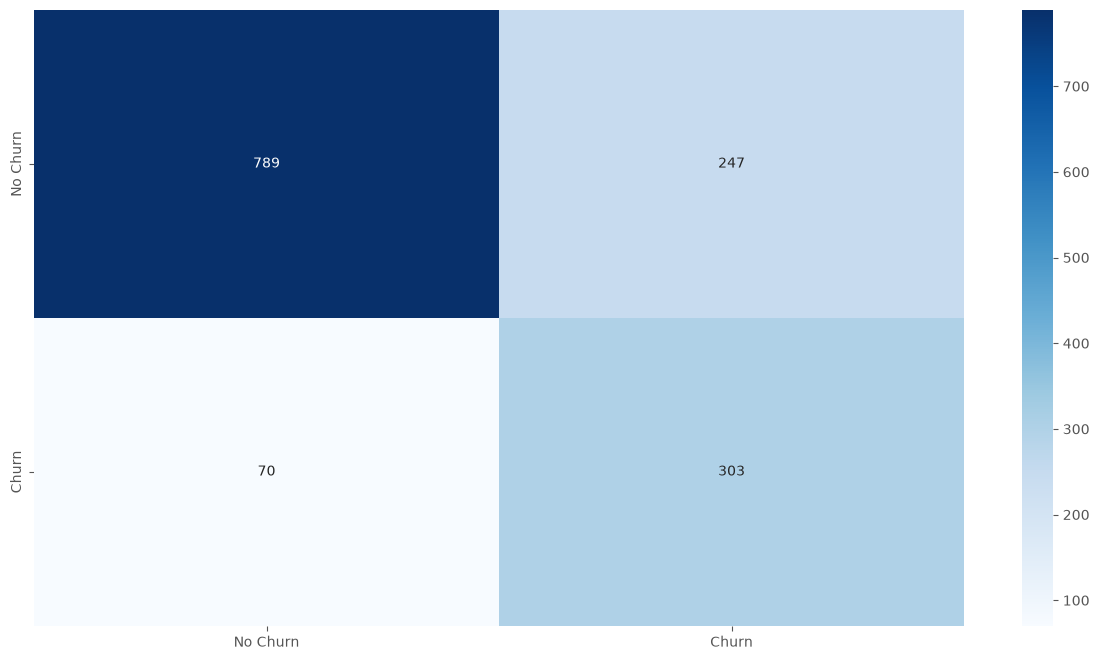

In [61]:
print(classification_report(y_test, y_pred_final))
plt.figure(figsize=(15, 8))
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])

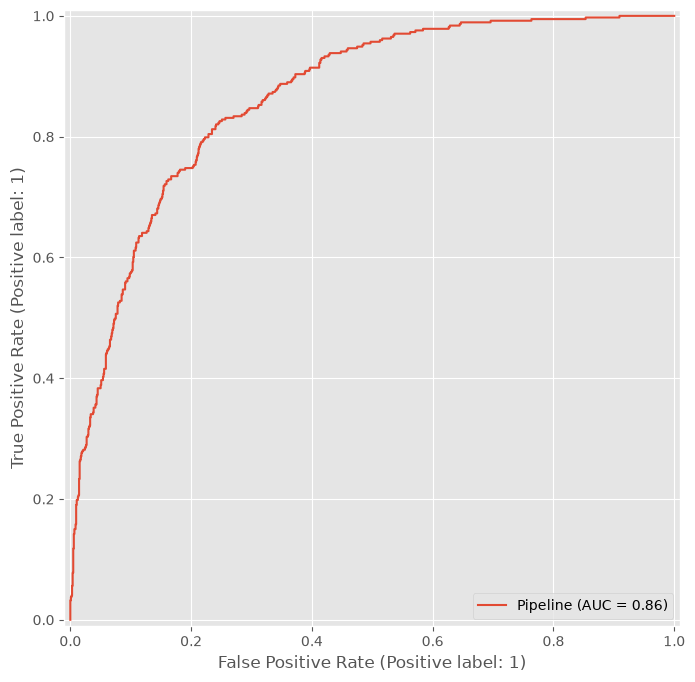

In [64]:
fig,ax=plt.subplots(figsize=(20,8))
RocCurveDisplay.from_estimator(final_model_selected,x_test,y_test,ax=ax)  


In [67]:
from pathlib import Path
import mlflow
import mlflow.sklearn

project_root=Path.cwd().parent.resolve()
tracking_dir=project_root / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{tracking_dir.as_posix()}")
mlflow.set_experiment("Customer_Churn")
with mlflow.start_run(run_name="Customer_Churn") as run :
    mlflow.sklearn.log_model(final_model_selected,artifact_path="final_model")
    mlflow.log_params(best_params)
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, y_pred_final),
        "recall": recall_score(y_test, y_pred_final),
        "precision": precision_score(y_test, y_pred_final),
    })

print("Tracking URI:", mlflow.get_tracking_uri())
print("Run ID:", run.info.run_id)

2026/11/15 04:44:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/15 04:44:21 INFO mlflow.store.db.utils: Updating database tables
2026/11/15 04:44:23 INFO mlflow.tracking.fluent: Experiment with name 'Customer_Churn' does not exist. Creating a new experiment.
2026/11/15 04:44:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/15 04:44:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Tracking URI: sqlite:///C:/Users/braab/Desktop/ML_proj/mlflow.db
Run ID: 061c78e7abd441eaba455f9b2b5713e3


In [69]:
print(tracking_dir.exists())

True
